# Dataset Creation - Part A

**Task:** binary classification of `RainTomorrow` - will at least 1.0 mm of precipitation fall tomorrow, in one of 6 cities, based on today's daily weather.

**Pipeline**
1. `data_collection.py` - downloads raw JSON from the Open-Meteo Historical Weather API into `data/raw/<city>/`.
2. `sensing.py` - merges all JSON files into `data/raw/sensed_data.csv` (one row per location + date).
3. **This notebook** - loads `sensed_data.csv`, checks data quality, explores the data, creates the target `RainTomorrow`, and saves `data/processed/final_dataset.csv`.

For every step we document: why we did it, what the output shows, what we learned, and the implications for the next steps.

In [1]:
# Libraries and paths used throughout the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
RAW_PATH = Path("data/raw/sensed_data.csv")              # output of sensing.py
PROCESSED_PATH = Path("data/processed/final_dataset.csv")  # output of this notebook

In [2]:
# Load the merged table: one row per (location, date), 18 daily variables
df = pd.read_csv(RAW_PATH)
print(df.shape)
df.head()

(36942, 20)


,location,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_direction_10m_dominant,relative_humidity_2m_mean,dew_point_2m_mean,pressure_msl_mean,cloud_cover_mean,wind_gusts_10m_max,sunshine_duration,shortwave_radiation_sum,et0_fao_evapotranspiration
0,berlin,2010-01-01,73,-1.6,-3.2,-2.5,-7.2,3.2,0.0,12.0,16.3,44,86,-4.6,998.2,99,31.3,0.00,1.82,0.30
1,berlin,2010-01-02,71,-1.2,-5.7,-3.2,-7.6,1.1,0.0,9.0,15.8,324,90,-4.6,1011.5,97,23.0,2114.82,2.55,0.23
2,berlin,2010-01-03,71,-4.9,-8.9,-6.7,-10.5,0.0,0.0,0.0,7.3,49,93,-7.6,1020.2,94,19.4,12470.87,2.50,0.14
3,berlin,2010-01-04,3,-6.3,-9.6,-7.6,-12.0,0.0,0.0,0.0,13.0,215,90,-9.0,1017.6,92,23.8,0.00,2.02,0.16
4,berlin,2010-01-05,3,-5.4,-11.7,-7.7,-12.3,0.0,0.0,0.0,11.2,176,88,-9.4,1010.3,90,21.6,18052.82,2.74,0.21


## Data Understanding (1/4): Data Origin and Variable Dictionary

**Why:** before analysing numbers we must know what each variable measures, in which unit, and what kind of variable it is - this decides which plots, statistics and encodings are valid.

**Where the data comes from (verified in the Open-Meteo Historical Weather API documentation):**
- The values are **not raw station measurements**. They come from *reanalysis* models: a weather model that is continuously corrected by observations (stations, satellites, aircraft, buoys, radar). This is why there are no gaps and almost no impossible values.
- The default `best_match` setting (used by us) **combines several models**: ERA5 (~25 km grid) and ERA5-Land (~11 km) for older dates, and ECMWF IFS (9 km) **from 2017 onwards**. Open-Meteo itself recommends using ERA5 only when long-term consistency is needed. We examine the effect of this model switch in the data quality section.
- Each value describes a **grid cell** (9-25 km), not a point; the returned coordinates are the cell centre.
- Daily values are 24-hour aggregations of hourly values in the **local time zone** of each city (`timezone=auto`).

**Variable types used below:**
- *Continuous* - any real value in a range (histogram + PDF).
- *Discrete count* - whole numbers (e.g. hours).
- *Circular* - an angle: 359 deg and 1 deg are neighbours, so the plain number is misleading.
- *Categorical* - a label; arithmetic on it is meaningless (bar chart, not histogram).
- *Derived* - computed by the model from other variables, so it may duplicate information.

In [3]:
# Variable dictionary: meaning, unit and type of every column (from the API documentation)
var_info = [
    # name, meaning, unit, type, group
    ("location", "City the grid cell belongs to (added by sensing.py)", "-", "categorical (6 values)", "identifier"),
    ("date", "Local calendar day", "date", "time index", "identifier"),
    ("weather_code", "Most severe weather condition of the day (WMO code), derived by the model from cloud cover and precipitation", "WMO code", "ordinal categorical, derived", "required"),
    ("temperature_2m_max", "Maximum air temperature 2 m above ground", "deg C", "continuous", "required"),
    ("temperature_2m_min", "Minimum air temperature 2 m above ground", "deg C", "continuous", "required"),
    ("temperature_2m_mean", "Mean air temperature over 24 hours", "deg C", "continuous", "required"),
    ("apparent_temperature_mean", "Feels-like temperature (combines temperature, wind chill, humidity, radiation)", "deg C", "continuous, derived", "required"),
    ("precipitation_sum", "Total precipitation: rain + showers + snow (water equivalent)", "mm", "continuous, zero-inflated", "required"),
    ("rain_sum", "Liquid precipitation only", "mm", "continuous, zero-inflated", "required"),
    ("precipitation_hours", "Number of hours with precipitation", "hours (0-24)", "discrete count", "required"),
    ("wind_speed_10m_max", "Maximum wind speed 10 m above ground", "km/h", "continuous", "required"),
    ("wind_direction_10m_dominant", "Dominant direction the wind blows FROM (0 = north, 90 = east)", "degrees", "circular", "required"),
    ("relative_humidity_2m_mean", "Mean relative humidity", "% (0-100)", "continuous, bounded", "extra"),
    ("dew_point_2m_mean", "Mean dew point: temperature at which the air becomes saturated", "deg C", "continuous", "extra"),
    ("pressure_msl_mean", "Mean air pressure reduced to sea level (low pressure = storm systems)", "hPa", "continuous", "extra"),
    ("cloud_cover_mean", "Mean share of the sky covered by clouds", "% (0-100)", "continuous, bounded", "extra"),
    ("wind_gusts_10m_max", "Maximum wind gust 10 m above ground", "km/h", "continuous", "extra"),
    ("sunshine_duration", "Seconds of direct sunshine (direct irradiance > 120 W/m2, WMO definition)", "seconds", "continuous", "extra"),
    ("shortwave_radiation_sum", "Total solar energy reaching the ground", "MJ/m2", "continuous", "extra"),
    ("et0_fao_evapotranspiration", "Reference evaporation of a watered grass field, computed from temperature, wind, humidity and radiation", "mm", "continuous, derived", "extra"),
]
var_table = pd.DataFrame(var_info, columns=["variable", "meaning", "unit", "type", "group"]).set_index("variable")

# Add what we actually observe in the data, to check the documentation against reality
numeric = df.select_dtypes(include="number")
var_table["n_unique"] = df.nunique()
var_table["min"] = numeric.min().round(2)
var_table["mean"] = numeric.mean().round(2)
var_table["max"] = numeric.max().round(2)

pd.set_option("display.max_colwidth", 90)
var_table

,meaning,unit,type,group,n_unique,min,mean,max
variable,,,,,,,,
location,City the grid cell belongs to (added by sensing.py),-,categorical (6 values),identifier,6,NaN,NaN,NaN
date,Local calendar day,date,time index,identifier,6157,NaN,NaN,NaN
weather_code,"Most severe weather condition of the day (WMO code), derived by the model from cloud c...",WMO code,"ordinal categorical, derived",required,13,0.00,32.36,75.00
temperature_2m_max,Maximum air temperature 2 m above ground,deg C,continuous,required,505,-12.70,16.87,42.00
temperature_2m_min,Minimum air temperature 2 m above ground,deg C,continuous,required,469,-20.60,9.21,29.60
temperature_2m_mean,Mean air temperature over 24 hours,deg C,continuous,required,468,-16.80,12.99,34.90
apparent_temperature_mean,"Feels-like temperature (combines temperature, wind chill, humidity, radiation)",deg C,"continuous, derived",required,567,-21.80,11.29,38.80
precipitation_sum,Total precipitation: rain + showers + snow (water equivalent),mm,"continuous, zero-inflated",required,595,0.00,3.19,183.60
rain_sum,Liquid precipitation only,mm,"continuous, zero-inflated",required,587,0.00,3.05,183.60


**What the table shows:**
- **10 required + 8 extra** weather variables, plus 2 identifiers. The extra variables were added because each is physically linked to rain formation (moisture, pressure systems, clouds). *Test files:* the example raw file published with the assignment (`raw sample example`) holds **only the 10 required variables**, and two consecutive days. The extra variables may therefore be missing from the test files of Part B. We keep them in the dataset (Part B decides), and the end of the data-preparation section measures what is lost without them. All our preparation steps work row by row, so a file with any number of days can be prepared.
- **Two variables need special treatment later:** `weather_code` is categorical (its numbers are labels, the mean of 32.4 has no meaning) and `wind_direction_10m_dominant` is circular.
- **Three variables are derived by the model from other variables:** `weather_code`, `apparent_temperature_mean`, `et0_fao_evapotranspiration`. They may add little new information - checked in the relationships section.
- **Observed ranges match the documentation** (humidity and cloud cover within 0-100, precipitation hours within 0-24, no negative precipitation).

**Implication for the next steps:** the plots of prior probabilities must use bar charts for `location` and `weather_code`, and the derived and duplicated variables are the first candidates for removal in the preparation section.

In [4]:
# weather_code is derived from precipitation: check how the two relate
wmo_names = {0: "Clear sky", 1: "Mainly clear", 2: "Partly cloudy", 3: "Overcast",
             51: "Light drizzle", 53: "Moderate drizzle", 55: "Dense drizzle",
             61: "Slight rain", 63: "Moderate rain", 65: "Heavy rain",
             71: "Slight snowfall", 73: "Moderate snowfall", 75: "Heavy snowfall"}
code_check = df.groupby("weather_code").agg(
    days=("precipitation_sum", "size"),
    share_with_precipitation=("precipitation_sum", lambda s: round((s > 0).mean(), 3)),
    median_precipitation_mm=("precipitation_sum", "median"),
)
code_check.insert(0, "meaning", code_check.index.map(wmo_names))
code_check

,meaning,days,share_with_precipitation,median_precipitation_mm
weather_code,,,,
0,Clear sky,1129,0.000,0.00
1,Mainly clear,1194,0.000,0.00
2,Partly cloudy,1529,0.000,0.00
3,Overcast,12881,0.000,0.00
51,Light drizzle,7191,1.000,0.40
53,Moderate drizzle,3472,1.000,2.00
55,Dense drizzle,1407,1.000,3.90
61,Slight rain,3269,1.000,6.50
63,Moderate rain,2691,1.000,14.70


**What we learned:** `weather_code` is almost a coarse summary of precipitation: codes 0-3 appear only on days without precipitation, codes 51 and above only on days with precipitation (apart from a few snow days rounded to 0.0 mm), and the median amount grows with the code. Only 13 of the 28 WMO codes appear - fog, showers and thunderstorms never occur, because the model derives the code from cloud cover and precipitation only.

**Implication:** `weather_code` carries little information beyond `precipitation_sum` and `cloud_cover_mean`. For Naive Bayes (which assumes independent features) such duplication counts the same evidence twice, so this is a strong candidate for removal or for grouping into a few classes.

## Data Quality Checks

**Why:** before any analysis we need to know whether values are missing or physically impossible, because both distort statistics and models.

1. **Missing values** - count and ratio per column.
2. **Plausibility checks** - rules that must hold physically, e.g. the daily minimum temperature cannot exceed the maximum, rain (`rain_sum`) is part of total precipitation (`precipitation_sum`), amounts cannot be negative, a wind direction is between 0 and 360 degrees.

Note: Open-Meteo historical data is model-based (reanalysis, not raw station readings). This explains why very few errors are expected. The source model also changes over time - examined at the end of this section.

In [5]:
# 1. Missing values per column
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_ratio": df.isna().mean().round(4),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_ratio", ascending=False)
display(quality)

# 2. Plausibility checks: each rule counts the rows that VIOLATE it
checks = {
    "temp_min > temp_max": df["temperature_2m_min"] > df["temperature_2m_max"],
    "temp_mean outside [min, max]": (df["temperature_2m_mean"] < df["temperature_2m_min"])
                                    | (df["temperature_2m_mean"] > df["temperature_2m_max"]),
    "rain_sum > precipitation_sum": df["rain_sum"] > df["precipitation_sum"] + 1e-9,
    "negative precipitation": df["precipitation_sum"] < 0,
    "precipitation_hours outside [0, 24]": ~df["precipitation_hours"].between(0, 24),
    "precipitation > 0 but 0 hours": (df["precipitation_sum"] > 0) & (df["precipitation_hours"] == 0),
    "wind direction outside [0, 360]": ~df["wind_direction_10m_dominant"].between(0, 360),
    "humidity outside [0, 100]": ~df["relative_humidity_2m_mean"].between(0, 100),
    "cloud cover outside [0, 100]": ~df["cloud_cover_mean"].between(0, 100),
    "negative wind speed": df["wind_speed_10m_max"] < 0,
}
display(pd.Series({name: int(mask.sum()) for name, mask in checks.items()}, name="violations").to_frame())

# Show the violating rows (if any) so they can be inspected and handled
bad_mean = checks["temp_mean outside [min, max]"]
df.loc[bad_mean, ["location", "date", "temperature_2m_min", "temperature_2m_mean", "temperature_2m_max"]]

,missing_count,missing_ratio,dtype
location,0,0.0,object
date,0,0.0,object
weather_code,0,0.0,int64
temperature_2m_max,0,0.0,float64
temperature_2m_min,0,0.0,float64
temperature_2m_mean,0,0.0,float64
apparent_temperature_mean,0,0.0,float64
precipitation_sum,0,0.0,float64
rain_sum,0,0.0,float64
precipitation_hours,0,0.0,float64


,violations
temp_min > temp_max,0
"temp_mean outside [min, max]",1
rain_sum > precipitation_sum,0
negative precipitation,0
"precipitation_hours outside [0, 24]",0
precipitation > 0 but 0 hours,0
"wind direction outside [0, 360]",0
"humidity outside [0, 100]",0
"cloud cover outside [0, 100]",0
negative wind speed,0


,location,date,temperature_2m_min,temperature_2m_mean,temperature_2m_max
8713,london,2016-12-31,5.3,4.7,7.3


## Data Quality (continued): the Source Model Changed Twice

**Why:** the values are produced by weather models, and Open-Meteo switches models over time (see the data-origin section). If a variable is computed differently before and after some date, its values are **not comparable across time** - a real change in the data-generating process, not a change in the weather. For a model that will be tested on **future** dates this matters, because it should learn from data that looks like the data it will be tested on.

**How we check:** inside each city every variable is standardised (mean 0, standard deviation 1), so cities with different climates can be averaged. We then follow the average of the 6 cities over time (a 365-day moving average removes the seasons). A variable whose model changed shows a **step** at the change date. `precipitation_sum` is shown as a control.

**Two candidate change dates, both taken from documentation, not from the data:**
- **2017-01-01** - Open-Meteo documentation: ECMWF IFS (9 km) data is used "from 2017"; earlier dates come from ERA5 (25 km).
- **2024-11-12** - ECMWF implemented IFS Cycle 49r1 (a major upgrade that improved near-surface wind and temperature forecasts).

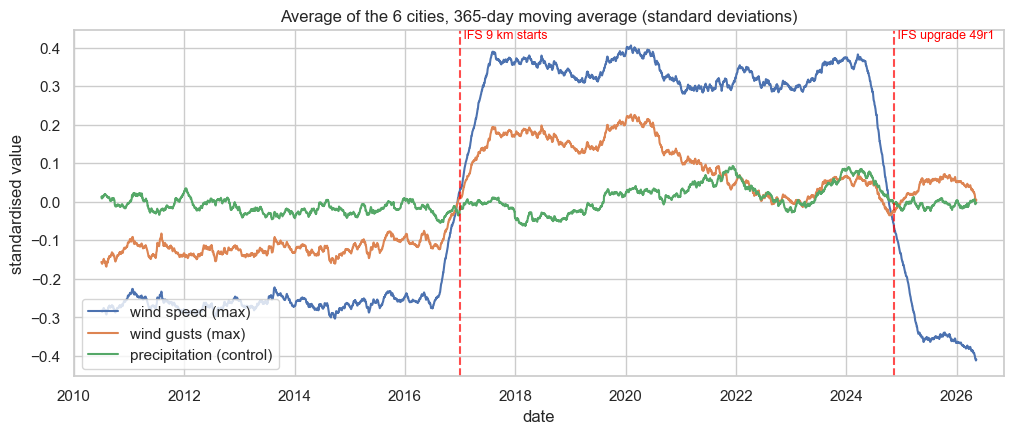

,2017-01-01,2024-11-12
wind_speed_10m_max,0.62,-0.72
wind_gusts_10m_max,0.28,0.00
relative_humidity_2m_mean,-0.03,-0.25
temperature_2m_min,-0.07,0.12
apparent_temperature_mean,-0.06,0.10
pressure_msl_mean,-0.04,0.10
precipitation_sum,0.01,-0.03
rain_sum,0.00,-0.03


In [6]:
# Standardise every numeric variable inside each city, then average the 6 cities for every day
num_cols = df.select_dtypes(include="number").columns.drop("weather_code")
dates = pd.to_datetime(df["date"])
city_mean = df.groupby("location")[num_cols].transform("mean")
city_std = df.groupby("location")[num_cols].transform("std")
daily_z = ((df[num_cols] - city_mean) / city_std).groupby(dates).mean()   # unit: standard deviations

BREAKS = {"2017-01-01": "IFS 9 km starts", "2024-11-12": "IFS upgrade 49r1"}

fig, ax = plt.subplots(figsize=(12, 4.5))
for col, label in [("wind_speed_10m_max", "wind speed (max)"),
                   ("wind_gusts_10m_max", "wind gusts (max)"),
                   ("precipitation_sum", "precipitation (control)")]:
    daily_z[col].rolling(365, center=True).mean().plot(ax=ax, label=label)
for d, text in BREAKS.items():
    ax.axvline(pd.Timestamp(d), color="red", linestyle="--", alpha=0.7)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1], " " + text, color="red", va="top", ha="left", fontsize=9)
ax.set_title("Average of the 6 cities, 365-day moving average (standard deviations)")
ax.set_xlabel("date")
ax.set_ylabel("standardised value")
ax.legend(loc="lower left")
plt.show()

# Size of the step at each change date: mean of the 2 years after minus mean of the 2 years before
def step_at(change_date, years=2):
    c, w = pd.Timestamp(change_date), pd.DateOffset(years=years)
    before = daily_z.loc[c - w: c - pd.Timedelta(days=1)].mean()
    after = daily_z.loc[c: c + w - pd.Timedelta(days=1)].mean()
    return after - before

steps = pd.DataFrame({d: step_at(d) for d in BREAKS})
top = steps.abs().max(axis=1).sort_values(ascending=False).head(6).index.tolist()
shown = top + [c for c in ["precipitation_sum", "rain_sum"] if c not in top]
steps.loc[shown].round(2)

In [7]:
# Independent check 1: without using any documentation, which single date in mid-2024..mid-2025
# splits the wind-speed series most sharply (largest difference between the mean before and after)?
w = daily_z["wind_speed_10m_max"].loc["2024-06-01":"2025-06-30"]
jump = {d: abs(w.loc[:d].mean() - w.loc[d:].mean()) for d in w.index[30:-30]}
print("date with the largest wind-speed jump:", max(jump, key=jump.get).date())

# Independent check 2: is the step visible in every city? Yearly mean of the maximum wind speed (km/h)
(df.assign(year=dates.dt.year)
   .pivot_table(index="location", columns="year", values="wind_speed_10m_max")
   .loc[:, 2015:2026].round(1))

date with the largest wind-speed jump: 2024-11-13


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
location,,,,,,,,,,,,
berlin,18.3,16.7,20.2,19.7,20.3,20.0,18.9,19.8,20.7,19.8,15.5,15.3
london,21.8,19.9,21.6,21.7,21.8,23.6,21.1,21.5,22.4,21.6,16.0,16.2
new_york,16.4,17.3,21.8,22.1,21.5,22.2,21.3,23.0,20.9,20.3,16.1,15.6
sydney,16.2,16.7,21.8,22.4,21.6,21.6,20.9,20.7,20.7,21.3,19.6,17.6
tokyo,20.2,20.0,27.4,27.5,27.3,26.3,27.0,25.9,26.9,25.5,13.9,13.6
vancouver,10.9,12.0,16.8,17.3,16.1,17.7,18.0,17.0,17.6,17.2,15.2,14.9


**What the plot and the tables show:**
- **Wind speed has a clear step at both dates:** it rises by about 0.6 standard deviations in 2017 and falls by about 0.7 in November 2024, back to roughly its level before 2017. The yearly table shows the same direction in **all 6 cities** at each date, which a change in the real climate would not do, but a change of the model does.
- **Wind gusts have a step only in 2017** (about +0.3). They then drift down during 2020-2023 and show no step in 2024.
- **The step in November 2024 matches the date of the ECMWF upgrade almost exactly:** the date with the largest wind-speed jump, found without using the documentation, is within a day of the upgrade. After it the new level stays stable until the end of the data.
- **`precipitation_sum` - the variable that defines our target - shows no step.** The label `RainTomorrow` is therefore consistent over the whole period; what changes is the description of the day (mainly wind, and to a lesser degree relative humidity, about -0.25 in 2024).
- The one implausible row found in the quality checks (London, 2016-12-31, mean temperature below the minimum) lies on the last day before the first change date. This may be related, but we have not proven it.

**Implications:**
1. The data is **not one homogeneous source**: three periods exist (before 2017, 2017 to November 2024, after November 2024). This limits how well the data represents the future.
2. Part B tests on days **after** our collection date. Open-Meteo will most likely serve them from the newest model, i.e. from the third period (an assumption we cannot check before the test files are released).
3. How much this actually harms a model, and which training period is best, is a modelling question. It should be checked in Part B with a validation set taken from the most recent months, not decided now by looking at wind plots.

## Prior Probabilities (1/2): Continuous Variables

**Why:** the a-priori (prior) probability of a variable is its distribution on its own, without conditioning on any other variable. It shows which values are typical and which are rare, and whether a simple shape such as a bell curve is realistic - important for models such as Naive Bayes, which assume a shape. For continuous variables we show a histogram with a smooth density estimate (the probability density function, PDF).

**Which variables:** three continuous variables with three different shapes - temperature (several peaks), precipitation (a pile-up at zero and a long tail) and humidity (bounded and skewed). The target and the two categorical variables (`location`, `weather_code`) follow after the target is created.

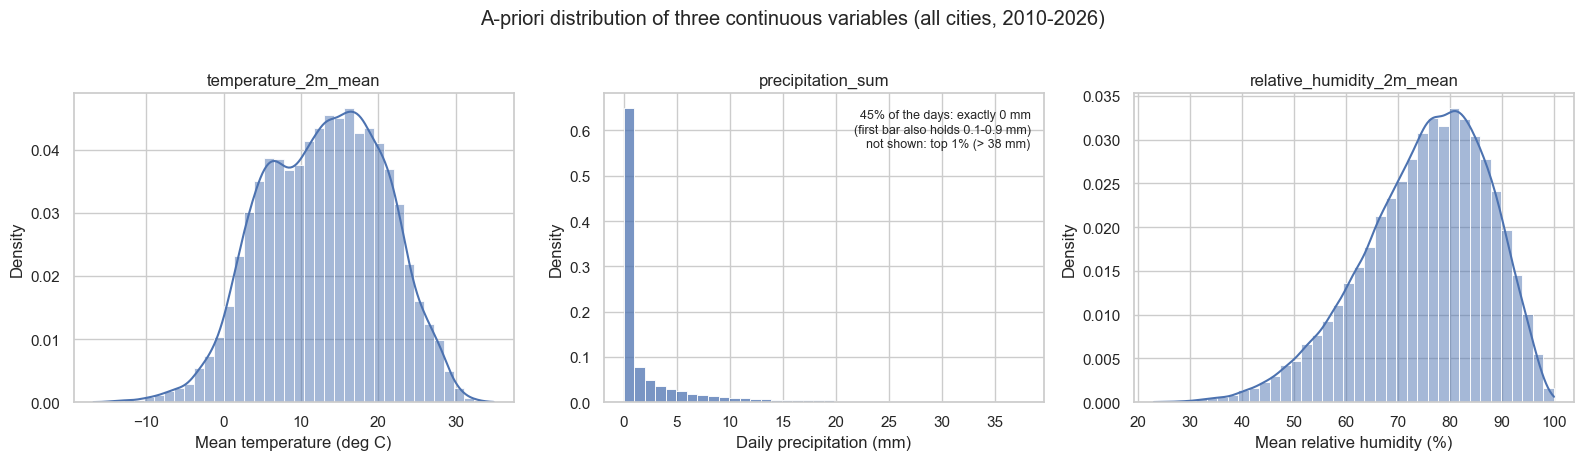

,temperature_2m_mean,precipitation_sum,relative_humidity_2m_mean
count,36942.00,36942.00,36942.00
mean,12.99,3.19,75.15
std,7.73,7.69,12.03
min,-16.80,0.00,23.00
50%,13.30,0.20,77.00
99%,28.50,37.70,96.00
max,34.90,183.60,100.00


In [8]:
# Three continuous variables with three different shapes
priors = [("temperature_2m_mean", "Mean temperature (deg C)"),
          ("precipitation_sum", "Daily precipitation (mm)"),
          ("relative_humidity_2m_mean", "Mean relative humidity (%)")]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (col, label) in zip(axes, priors):
    values = df[col]
    if col == "precipitation_sum":
        # Many days have exactly 0 mm: a point mass, not a smooth density, so no smoothed curve (kde)
        # is drawn and the zero share is written on the plot. The longest 1% of the tail is not shown.
        zero_share = (values == 0).mean()
        cut = values.quantile(0.99)
        sns.histplot(values[values <= cut], binwidth=1, stat="density", ax=ax)
        ax.text(0.97, 0.95, f"{zero_share:.0%} of the days: exactly 0 mm\n(first bar also holds 0.1-0.9 mm)\nnot shown: top 1% (> {cut:.0f} mm)",
                transform=ax.transAxes, ha="right", va="top", fontsize=9)
    elif col == "relative_humidity_2m_mean":
        # given in whole percent, so every bin covers exactly 2 whole values
        sns.histplot(values, binwidth=2, kde=True, stat="density", ax=ax)
    else:
        sns.histplot(values, bins=40, kde=True, stat="density", ax=ax)
    ax.set_title(col)
    ax.set_xlabel(label)
    ax.set_ylabel("Density")
plt.suptitle("A-priori distribution of three continuous variables (all cities, 2010-2026)", y=1.02)
plt.tight_layout()
plt.show()

# Numbers behind the plots
df[[c for c, _ in priors]].describe(percentiles=[.5, .99]).round(2)

**What the priors teach:**
- **`temperature_2m_mean`** has no single bell: mean 13.0 deg C, standard deviation 7.7, and two weak peaks (around 7 and 17 deg C). The peaks come from mixing climates: the four cool cities (Berlin, London, New York, Vancouver) have a mean of 10-12 deg C, Tokyo and Sydney 16-18. One normal distribution describes it poorly; it makes more sense to read it together with `location` and the season.
- **`precipitation_sum`** is not a smooth density: 45.5% of the days have exactly 0 mm and another 18.3% have less than 1 mm. The median is 0.2 mm, but the mean (3.2 mm) is far higher because of rare, very wet days (99th percentile 38 mm, maximum 184 mm). It is the clearest example of a variable far from a normal distribution, and it shows why the 1.0 mm threshold of the target matters: almost one day in five has some drizzle that still counts as "no rain".
- **`relative_humidity_2m_mean`** is bounded by 100% and skewed to the left: most days are humid (median 77%) and dry days form the long tail (minimum 23%). Near the upper bound a normal distribution would assign probability to impossible values above 100%.

## Target Creation: RainTomorrow

**Rule (from the assignment):** within each `location`, after sorting by `date`, `RainTomorrow = 1` if the **next day's** `precipitation_sum` is at least 1.0 mm, otherwise 0.

- `precipitation_sum` (not `rain_sum`) is used, because it includes snow.
- The 1.0 mm threshold ignores trace amounts (drizzle of 0.1 mm is not a "rainy day").
- The last day of each location has no "tomorrow", so it is removed.
- Next-day information is used **only** for the label, never as a feature (otherwise the model would see the answer - data leakage).

In [9]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["location", "date"]).reset_index(drop=True)

# shift(-1) inside each location = the value of the next row of the same city
next_precip = df.groupby("location")["precipitation_sum"].shift(-1)
next_date = df.groupby("location")["date"].shift(-1)

# The label is valid only if the next row is really the next calendar day.
# This drops the last day of each location AND the day before any gap in the data
# (e.g. a missing year), so no row gets a label from a different date.
has_tomorrow = (next_date - df["date"]).dt.days.eq(1)
print("rows without a real 'tomorrow' (last day or gap):", int((~has_tomorrow).sum()))

df["RainTomorrow"] = (next_precip >= 1.0).astype(int)
df = df[has_tomorrow].reset_index(drop=True)
df[["location", "date", "precipitation_sum", "RainTomorrow"]].head(10)

rows without a real 'tomorrow' (last day or gap): 6


,location,date,precipitation_sum,RainTomorrow
0,berlin,2010-01-01,3.2,1
1,berlin,2010-01-02,1.1,0
2,berlin,2010-01-03,0.0,0
3,berlin,2010-01-04,0.0,0
4,berlin,2010-01-05,0.0,0
5,berlin,2010-01-06,0.0,0
6,berlin,2010-01-07,0.0,0
7,berlin,2010-01-08,0.3,1
8,berlin,2010-01-09,11.3,1
9,berlin,2010-01-10,7.3,1


In [10]:
# Missing-value rule: a gap is filled with the median of the SAME city.
# A median over all cities would mix different climates (e.g. Sydney and Berlin).
# The medians are computed once, here, from the training data and stored in CITY_MEDIANS, so that the
# raw test files of Part B are filled with the TRAINING medians (inside prepare_features, below).
num_cols = df.select_dtypes(include=["number"]).columns.drop("RainTomorrow")
print("missing values in the training data:", int(df[num_cols].isna().sum().sum()))
CITY_MEDIANS = df.groupby("location")[num_cols].median()
print("stored medians:", CITY_MEDIANS.shape[0], "cities x", CITY_MEDIANS.shape[1], "variables")

missing values in the training data: 0
stored medians: 6 cities x 18 variables


## Prior Probabilities (2/2): the Target and the Categorical Variables

**Why:** the same idea for discrete variables. A bar chart shows the share of every value. The target `RainTomorrow` is included here, because it exists only after the target-creation step above; its prior is the most important one, because it tells us how balanced the problem is.

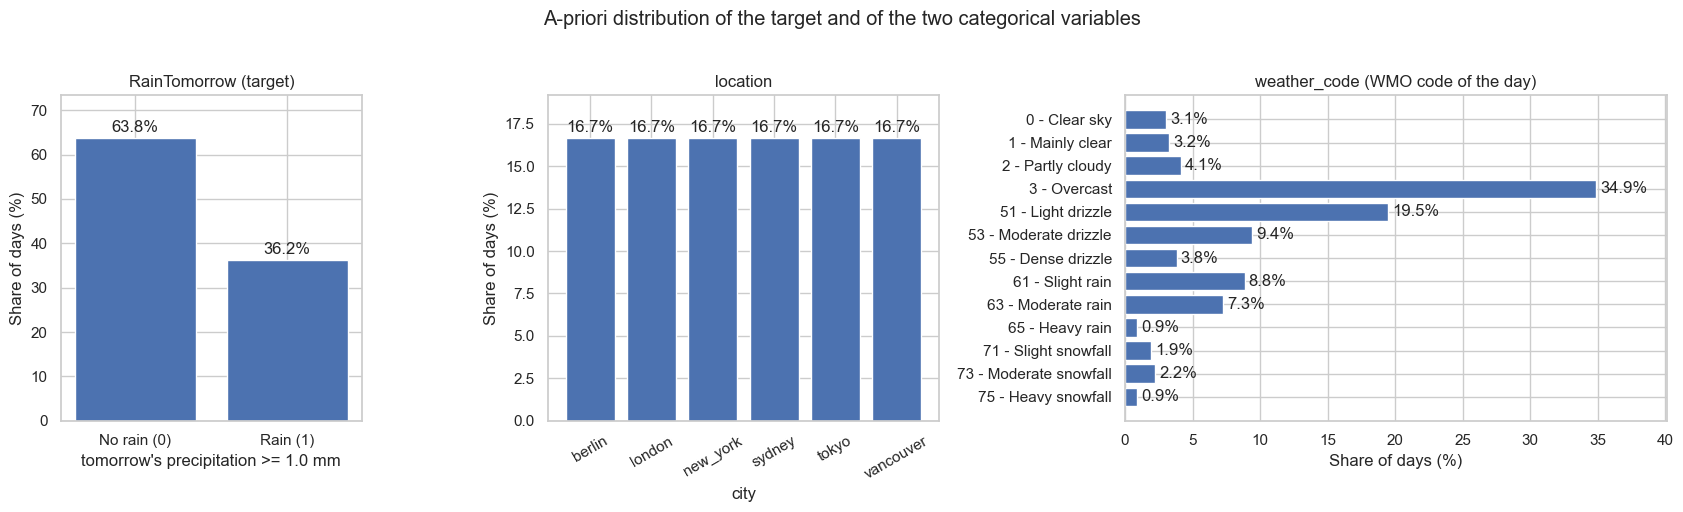

Share of rain days tomorrow, per city:
location
berlin       0.336
london       0.359
new_york     0.338
sydney       0.323
tokyo        0.366
vancouver    0.452

Majority / minority ratio of the target: 1.76 : 1


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1.3, 1.8]})

def bar_with_percent(ax, share, labels, title, xlabel):
    bars = ax.bar(labels, share.values * 100, color=sns.color_palette()[0])
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in share.values], padding=2)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Share of days (%)")
    ax.set_ylim(0, share.max() * 100 * 1.15)

# 1. The target
target_share = df["RainTomorrow"].value_counts(normalize=True).sort_index()
bar_with_percent(axes[0], target_share, ["No rain (0)", "Rain (1)"], "RainTomorrow (target)", "tomorrow's precipitation >= 1.0 mm")

# 2. Location
location_share = df["location"].value_counts(normalize=True).sort_index()
bar_with_percent(axes[1], location_share, location_share.index, "location", "city")
axes[1].tick_params(axis="x", rotation=30)

# 3. weather_code: horizontal bars, so the meaning of every code can be read
#    (wmo_names was defined in the data-understanding section)
code_share = df["weather_code"].value_counts(normalize=True).sort_index()
ax = axes[2]
bars = ax.barh([f"{c} - {wmo_names[c]}" for c in code_share.index], code_share.values * 100, color=sns.color_palette()[0])
ax.bar_label(bars, labels=[f"{v:.1%}" for v in code_share.values], padding=3)
ax.invert_yaxis()
ax.set_xlim(0, code_share.max() * 100 * 1.15)
ax.set_title("weather_code (WMO code of the day)")
ax.set_xlabel("Share of days (%)")

plt.suptitle("A-priori distribution of the target and of the two categorical variables", y=1.02)
plt.tight_layout()
plt.show()

print("Share of rain days tomorrow, per city:")
print(df.groupby("location")["RainTomorrow"].mean().round(3).to_string())
print(f"\nMajority / minority ratio of the target: {target_share.max() / target_share.min():.2f} : 1")

**What the priors teach:**
- **`RainTomorrow`:** rain follows 36.2% of the days (13,380 of 36,936), so about two days in three are dry.
- **`location`:** exactly 1/6 for every city. This is not a finding but the result of our sampling - the same period was collected for each city.
- **`weather_code`:** overcast is the most common day (34.9%), then light drizzle (19.5%); clear days are rare (3.1%, and only 10.4% for the three clear or partly cloudy codes together). Only 13 of the 28 WMO codes occur.

### Is the data balanced?
**Partly.** The target is split 63.8% / 36.2%, a ratio of 1.76 : 1 - not balanced, but not extreme. The consequence is that accuracy alone is misleading: always predicting "no rain" is right 63.8% of the time. In Part B the models should also be judged by measures that look at the rain class (for example AUC, or recall and precision of "rain"). The prior also depends on the city: the share of rain days is 32.3% in Sydney and 45.2% in Vancouver, so `location` carries information about the target.

### Does the data represent reality?
**Only partly:**
- **For:** 17 years of daily values, no missing values, and a rain-day share of 32-45% that is realistic for temperate cities.
- **Against:** (1) six cities, all in temperate or subtropical climates and each with the same weight - there are no tropical, desert or polar climates, so the result should be expected to work for similar cities, not for any place on Earth; (2) every value describes a 9-25 km grid cell produced by a model, not a station measurement; (3) the source model changed twice (previous section), so the data is not one homogeneous source; (4) "rain" is defined by the 1.0 mm threshold, so the 18.3% of the days with less than 1 mm of precipitation count as dry.

## Relationships Between Variables

**Why:** relationships show which variables carry information about tomorrow's rain and which only repeat each other. We look at three relationships - an expected one, an expected one with a consequence for the models, and an unexpected one - and then at every variable against the target.

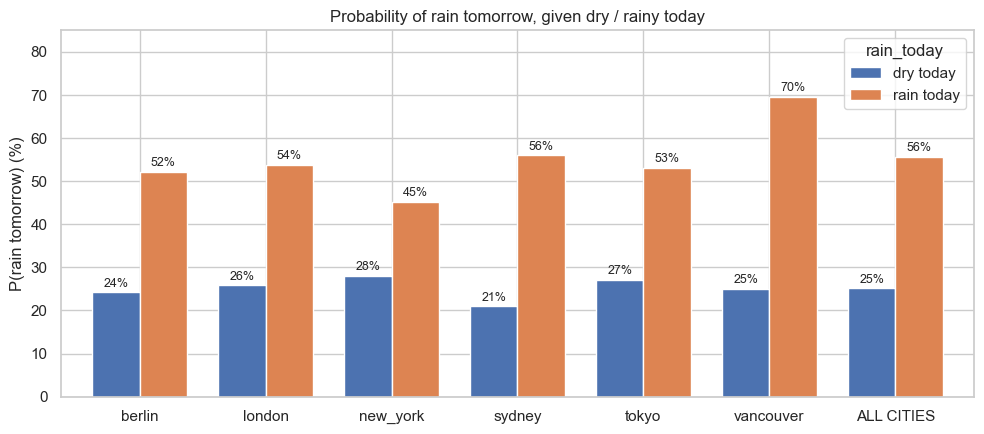

rain_today,dry today,rain today
location,,
berlin,0.242,0.521
london,0.258,0.539
new_york,0.280,0.453
sydney,0.210,0.560
tokyo,0.271,0.531
vancouver,0.251,0.696
ALL CITIES,0.252,0.557


In [12]:
# Relationship 1: does rain today predict rain tomorrow? (conditional probability, per city)
rain_today = (df["precipitation_sum"] >= 1.0).astype(int).rename("rain_today")
p_tomorrow = df.groupby(["location", rain_today])["RainTomorrow"].mean().unstack()
p_tomorrow.loc["ALL CITIES"] = df.groupby(rain_today)["RainTomorrow"].mean()
p_tomorrow = p_tomorrow.rename(columns={0: "dry today", 1: "rain today"})

ax = (p_tomorrow * 100).plot(kind="bar", figsize=(10, 4.5), width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=2, fontsize=9)
ax.set_title("Probability of rain tomorrow, given dry / rainy today")
ax.set_xlabel("")
ax.set_ylabel("P(rain tomorrow) (%)")
ax.set_ylim(0, 85)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
p_tomorrow.round(3)

**Relationship 1 (expected): rain today predicts rain tomorrow.** After a rainy day the chance of rain tomorrow is 55.7%, after a dry day 25.2% - more than twice as high. Weather systems last longer than one day, so today's precipitation is the simplest hint about tomorrow's. The strength depends on the city: in Vancouver the chance rises from 25% to 70%, in New York only from 28% to 45%.

**Meaning:** the variables that describe today's rain (`precipitation_sum`, `rain_sum`, `precipitation_hours`, `weather_code`) will probably be among the most useful features, and the city changes how much weight they deserve.

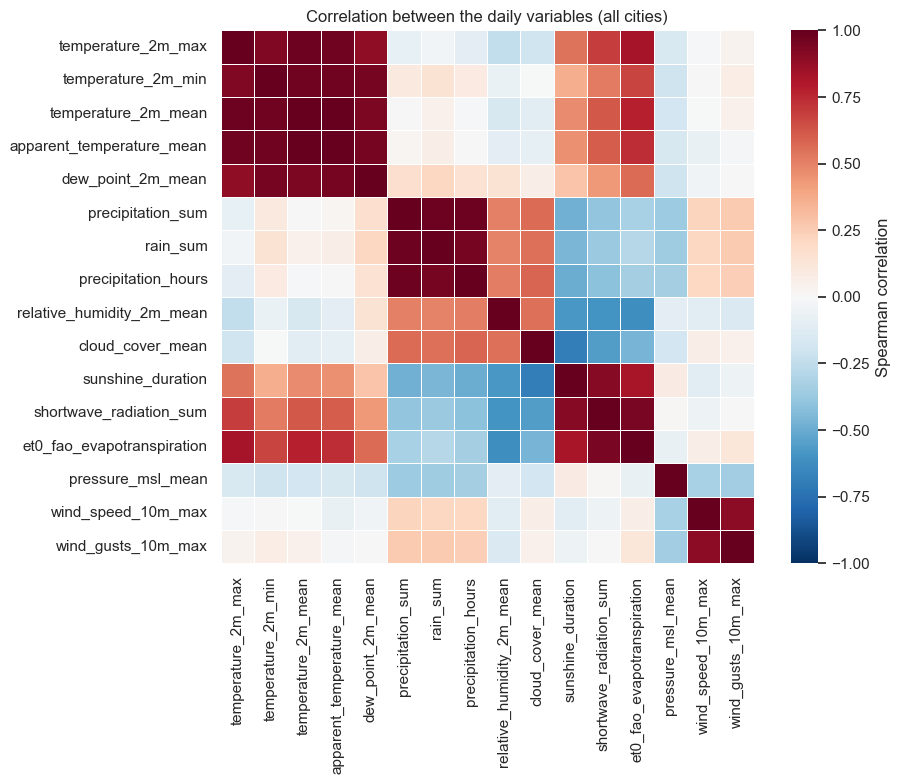

,variable 1,variable 2,correlation
0,temperature_2m_mean,apparent_temperature_mean,0.994
1,precipitation_sum,rain_sum,0.981
2,temperature_2m_max,temperature_2m_mean,0.980
3,precipitation_sum,precipitation_hours,0.980
4,temperature_2m_min,temperature_2m_mean,0.976
5,temperature_2m_min,apparent_temperature_mean,0.974
6,temperature_2m_max,apparent_temperature_mean,0.972
7,rain_sum,precipitation_hours,0.959
8,apparent_temperature_mean,dew_point_2m_mean,0.957
9,temperature_2m_min,dew_point_2m_mean,0.953


In [13]:
# Relationship 2: which variables say the same thing? Spearman correlation between the numeric variables
# (wind direction is an angle and weather_code a category, so they are left out)
order = ["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "apparent_temperature_mean", "dew_point_2m_mean",
         "precipitation_sum", "rain_sum", "precipitation_hours",
         "relative_humidity_2m_mean", "cloud_cover_mean", "sunshine_duration", "shortwave_radiation_sum", "et0_fao_evapotranspiration",
         "pressure_msl_mean", "wind_speed_10m_max", "wind_gusts_10m_max"]
corr = df[order].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"label": "Spearman correlation"})
plt.title("Correlation between the daily variables (all cities)")
plt.tight_layout()
plt.show()

# The strongest pairs, as numbers
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("correlation").reset_index()
pairs.columns = ["variable 1", "variable 2", "correlation"]
pairs[pairs["correlation"].abs() >= 0.9].sort_values("correlation", ascending=False).round(3).reset_index(drop=True)

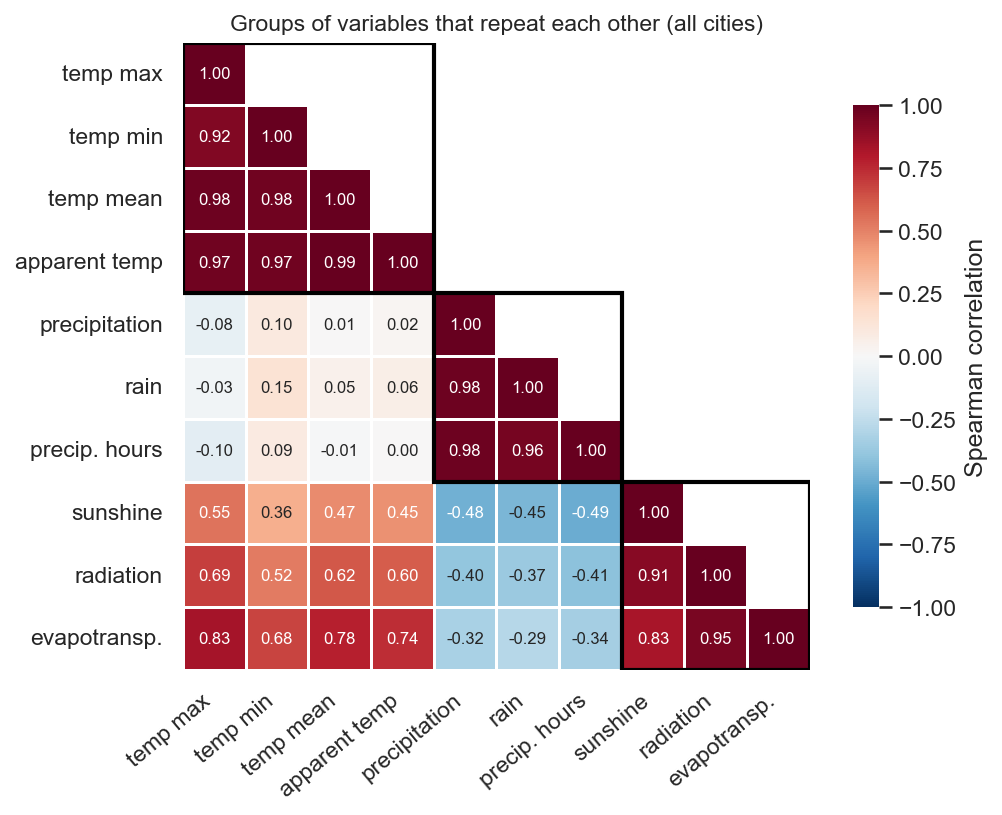

In [14]:
# Figure for the report (relationship 2): only the three groups of variables that repeat each other,
# with the correlations written in the cells, so the numbers in the text can be read off the figure
groups = [["temperature_2m_max", "temperature_2m_min", "temperature_2m_mean", "apparent_temperature_mean"],
          ["precipitation_sum", "rain_sum", "precipitation_hours"],
          ["sunshine_duration", "shortwave_radiation_sum", "et0_fao_evapotranspiration"]]
labels = ["temp max", "temp min", "temp mean", "apparent temp", "precipitation", "rain", "precip. hours",
          "sunshine", "radiation", "evapotransp."]
group_corr = df[sum(groups, [])].corr(method="spearman")
group_corr.index = group_corr.columns = labels

fig, ax = plt.subplots(figsize=(7.2, 5.6), dpi=150)
sns.heatmap(group_corr, mask=np.triu(np.ones_like(group_corr, dtype=bool), k=1), cmap="RdBu_r", vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=0.5, square=True,
            cbar_kws={"label": "Spearman correlation", "shrink": 0.8}, ax=ax)
start = 0
for g in groups:                       # a frame around each group
    ax.add_patch(plt.Rectangle((start, start), len(g), len(g), fill=False, edgecolor="black", lw=2))
    start += len(g)
ax.grid(False)                         # the notebook style draws a grid over the empty half
ax.set_title("Groups of variables that repeat each other (all cities)", fontsize=11)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

**Relationship 2 (expected, with a consequence): many variables repeat each other.** The temperature variables (maximum, minimum, mean, apparent) correlate at 0.92-0.99 with each other and the dew point at 0.89-0.96 with them; the three precipitation variables at 0.96-0.98; solar radiation with sunshine (0.91) and with evaporation (0.95). The reason is physical: apparent temperature is computed from the temperature, rain is part of the precipitation, and evaporation is computed from temperature and radiation. The negative blocks (clouds and humidity against sunshine and radiation) are also expected: cloudy days get less sun.

**Meaning:** the 16 variables carry much less than 16 independent pieces of information. Naive Bayes assumes that the variables are independent, so repeated variables make it count the same evidence several times. This is the first place to look for variables to remove or combine in data preparation.

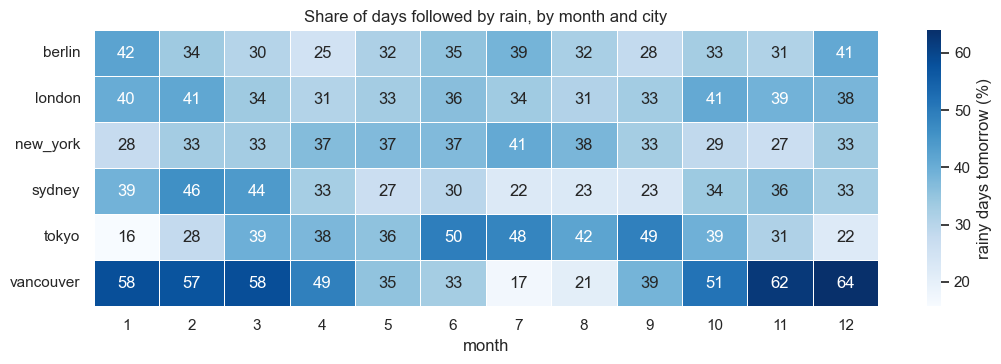

,difference between the wettest and driest month (percentage points)
location,
berlin,17.0
london,11.0
new_york,14.0
sydney,24.0
tokyo,34.0
vancouver,47.0


In [15]:
# Relationship 3: the share of rainy days tomorrow, by month and city
month = pd.to_datetime(df["date"]).dt.month.rename("month")
by_month = df.pivot_table(index=month, columns="location", values="RainTomorrow") * 100

plt.figure(figsize=(11, 3.8))
sns.heatmap(by_month.T, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5, cbar_kws={"label": "rainy days tomorrow (%)"})
plt.title("Share of days followed by rain, by month and city")
plt.xlabel("month")
plt.ylabel("")
plt.tight_layout()
plt.show()

# How much does the seasonal cycle vary inside each city? (highest minus lowest monthly share)
(by_month.max() - by_month.min()).round(0).rename("difference between the wettest and driest month (percentage points)").to_frame()

**Relationship 3 (unexpected): the seasons work in opposite ways in different cities.** In Vancouver 17% of the days in July are followed by rain but 64% of the days in December, a difference of 47 percentage points. In Tokyo rain peaks in the summer (48-50% in June, July and September) and is rarest in January (16%). Sydney, in the southern hemisphere, is reversed: 44-46% in February and March, 22-23% from July to September. In London (11 points) and New York (14 points) the share hardly changes during the year.

**Meaning:** over all cities together the month would show only a weak pattern, because the opposite cycles partly cancel out, but inside every city it is a strong signal. A feature derived from the month (in a circular form, because December is next to January) together with the city could add information that is hidden in the raw variables; the data-preparation section checks how much it really helps. The date is available in the raw files, so this feature can be built for the test files of Part B too.

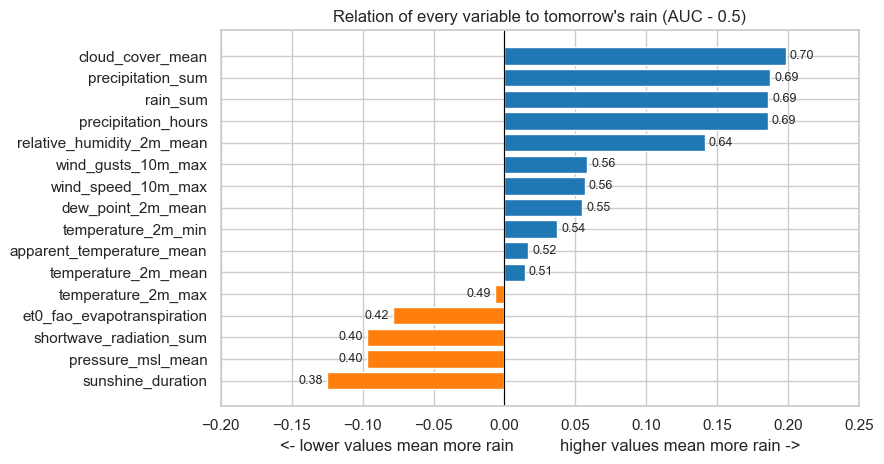

In [16]:
# Which variables are suspected to influence tomorrow's rain? One variable at a time, using AUC:
# 0.5 = no relation, above 0.5 = higher values mean more rain, below 0.5 = lower values mean more rain.
# Computed inside every city and averaged, so that differences between cities do not create a false relation.
from sklearn.metrics import roc_auc_score

auc_by_variable = {col: np.mean([roc_auc_score(g["RainTomorrow"], g[col]) for _, g in df.groupby("location")])
                   for col in order}
auc = pd.Series(auc_by_variable).sub(0.5).sort_values()

plt.figure(figsize=(9, 4.8))
colors = ["tab:blue" if v > 0 else "tab:orange" for v in auc.values]
bars = plt.barh(auc.index, auc.values, color=colors)
plt.bar_label(bars, labels=[f"{v + 0.5:.2f}" for v in auc.values], padding=3, fontsize=9)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Relation of every variable to tomorrow's rain (AUC - 0.5)")
plt.xlabel("<- lower values mean more rain          higher values mean more rain ->")
plt.xlim(-0.2, 0.25)
plt.tight_layout()
plt.show()

**Which variables are suspected to influence tomorrow's rain?** Taken one at a time, the strongest describe the sky and the moisture of today: cloud cover (AUC 0.70), today's precipitation (0.69 for each of the three precipitation variables) and relative humidity (0.64). Variables of clear, dry, high-pressure weather work in the opposite direction: sunshine (0.38), solar radiation (0.40), pressure (0.40) and evaporation (0.42) - lower values mean more rain, which fits meteorology (low pressure and clouds bring rain). Wind speed, gusts and dew point are weak (0.55-0.56). **The temperature variables are almost useless on their own (0.49-0.54)**, although temperature is the variable people look at first: rain falls at every temperature, so temperature matters only together with the season, the city or the humidity.

**Which variables can be removed?** According to this check none of them can be dismissed as unrelated: even the weakest one (maximum temperature, 0.49) has a plausible physical link, and a weak single-variable relation does not rule out a useful combination. The repeated variables (Relationship 2) are the better candidates for removal and are handled in data preparation.

*Limits:* this is a single-variable check on all the data. It cannot see combinations of variables, and it describes the data - it does not replace the model selection of Part B.

## Which Training Period? A Preliminary Check

**Why:** the previous section showed that the source model changed in 2017 and in November 2024. Before deciding whether to remove the older years, we check whether the change matters for prediction. This is only a **quick, preliminary check** - the real model comparison is Part B.

**How:**
- Features: all numeric daily variables except `weather_code` (derived from precipitation, see above) and the raw wind direction, which is replaced by its sine and cosine (an angle is circular). The city is added as 0/1 columns.
- **Validation = the last 12 months** (from 2025-11-10). The models are trained only on days **before** it, so the check imitates Part B: predict a future period from the past. The validation period is entirely inside the newest model period.
- Three training periods: all years, 2017 onwards, and only after the November 2024 upgrade.
- Two different models, because different models may react differently: Gradient Boosting (flexible) and Naive Bayes (the model of the course, which treats every variable separately).
- Metric: **AUC** (0.5 = guessing, 1.0 = perfect). It is independent of the 0.5 threshold and of the class balance.

In [17]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_auc_score

# Simple feature table: numeric variables, wind direction as sine / cosine, city as 0/1 columns
rad = np.deg2rad(df["wind_direction_10m_dominant"])
X = df.drop(columns=["location", "date", "weather_code", "wind_direction_10m_dominant", "RainTomorrow"])
X = X.assign(wind_dir_sin=np.sin(rad), wind_dir_cos=np.cos(rad))
X = pd.concat([X, pd.get_dummies(df["location"], dtype=float)], axis=1)
y = df["RainTomorrow"]

is_validation = df["date"] >= "2025-11-10"          # last 12 months
training_periods = {"all years (from 2010)": "2010-01-01",
                    "from 2017": "2017-01-01",
                    "after the Nov-2024 upgrade": "2024-11-13"}
models = {"Gradient Boosting": lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=0),
          "Naive Bayes": lambda: GaussianNB()}

rows = []
for period, start in training_periods.items():
    train = (df["date"] >= start) & ~is_validation   # only days before the validation period
    for model_name, make_model in models.items():
        model = make_model().fit(X[train], y[train])
        auc = roc_auc_score(y[is_validation], model.predict_proba(X[is_validation])[:, 1])
        rows.append({"training period": period, "training rows": int(train.sum()),
                     "model": model_name, "AUC": round(auc, 3)})

pd.DataFrame(rows).pivot(index=["training period", "training rows"], columns="model", values="AUC")

,model,Gradient Boosting,Naive Bayes
training period,training rows,,
after the Nov-2024 upgrade,2172,0.733,0.699
all years (from 2010),34752,0.771,0.688
from 2017,19410,0.769,0.692


**What we learned:**
- **Removing the years before 2017 makes almost no difference:** the AUC changes by about 0.004 for both models, even though the wind variables differ by 0.6-0.7 standard deviations between the periods.
- **Keeping only the two years after the November 2024 upgrade does not help consistently:** Naive Bayes improves slightly (about +0.01), but Gradient Boosting loses about 0.04, probably because about 2,200 rows are too few examples for a flexible model.
- This was a single split with one validation year, so small differences should not be over-interpreted. The check only shows that the model change is **not a large effect on prediction**, and that the effect depends on the model.

### Decision

**All years (2010-01-01 to 2026-11-09) stay in `final_dataset.csv`, together with the `date` column. No row is removed because of the model change.** The training period will be chosen in Part B with a proper validation set.

| Option we considered | Why we did / did not choose it |
|---|---|
| Remove everything before 2017 (our first idea) | It was based on the first step only. The second step (Nov 2024) was found later, so "2017 onwards" is not homogeneous either. The check above shows no consistent benefit from removing the older years. |
| Keep only the data after Nov 2024 | It is the period closest to the future test, but it has only about 2 years, so each season appears twice. It was clearly worse for Gradient Boosting. |
| Remove or rescale the wind variables | The course staff advised to remove at most one or two variables, and only if the link to the target is both implausible and not visible in the data. Wind is physically related to rain. |
| **Keep all years, document the shifts, decide in Part B** | Removing data without evidence of benefit loses information. The `date` column allows choosing any period later with one line of code. |

**Limits we accept:** the data is not one homogeneous source, and Part B's test files will most likely come from the newest model (an assumption). Whichever training period is chosen in Part B must be justified by validation on the most recent months.

## Data Preparation

**Principle:** the preparation should be small, and every step should have a reason that can be checked. The same steps have to work on the raw test files of Part B, so everything is written as one function, `prepare_features`. The course staff advised to remove at most one or two variables, so we first ask what really needs treatment: variables whose type needs a different encoding (`weather_code`, wind direction), an impossible value, and variables that repeat another one.

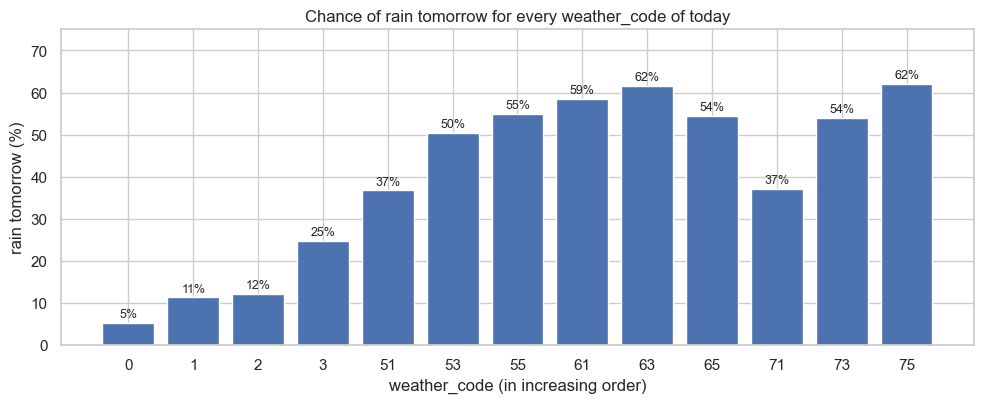

In [18]:
# weather_code: how does the chance of rain tomorrow change with the code? (to choose an encoding)
rain_by_code = df.groupby("weather_code")["RainTomorrow"].agg(["mean", "size"])

plt.figure(figsize=(10, 4.2))
bars = plt.bar(range(len(rain_by_code)), rain_by_code["mean"] * 100, color=sns.color_palette()[0])
plt.bar_label(bars, labels=[f"{v:.0%}" for v in rain_by_code["mean"]], padding=2, fontsize=9)
plt.xticks(range(len(rain_by_code)), rain_by_code.index)
plt.xlabel("weather_code (in increasing order)")
plt.ylabel("rain tomorrow (%)")
plt.title("Chance of rain tomorrow for every weather_code of today")
plt.ylim(0, 75)
plt.tight_layout()
plt.show()

**Encoding of `weather_code`.** The code is a category, but its numbers are ordered: 0-3 (from clear to overcast), 51-55 (drizzle), 61-65 (rain), 71-75 (snow). The chance of rain tomorrow rises almost steadily with the code, from 5% after a clear day to about 62% after moderate rain or heavy snow, with two exceptions: heavy rain (54%, but only 334 days) and light snow (37%). Therefore we keep the order and replace the code by its **rank** among the known codes (0 to 12). This uses one column instead of 13 separate 0/1 columns, which would raise the number of dimensions, and it spaces the values evenly instead of the jump from 3 to 51. A code that never occurred in training (for example 95, thunderstorm) gets the rank of the closest known code below it, so the test files cannot break the encoding.

In [19]:
# ---- Data preparation: ONE function, so that exactly the same steps can be applied to the raw test files of Part B ----
# The 13 WMO codes that occur in the training data. Written out (not computed from the table at hand), so the
# encoding stays exactly the same when the function runs on another file, e.g. the test files of Part B.
KNOWN_CODES = np.array([0, 1, 2, 3, 51, 53, 55, 61, 63, 65, 71, 73, 75])
assert set(df["weather_code"].unique()) == set(KNOWN_CODES)

def prepare_features(raw):
    """Turn the collected daily variables into the final feature table (works on a train or a test table)."""
    out = raw.copy()

    # 0. Missing values -> median of the same city, taken from the training data (CITY_MEDIANS, previous section)
    for col in CITY_MEDIANS.columns.intersection(out.columns):
        out[col] = out[col].fillna(out["location"].map(CITY_MEDIANS[col]))

    # 1. The single impossible value (mean temperature outside [min, max]) is moved to the nearest allowed value
    out["temperature_2m_mean"] = out["temperature_2m_mean"].clip(lower=out["temperature_2m_min"], upper=out["temperature_2m_max"])

    # 2. weather_code -> its rank among the known codes (0..12). The order is kept, one column is used instead of 13,
    #    and a code that never occurred in training gets the rank of the closest known code below it
    out["weather_code_rank"] = (np.searchsorted(KNOWN_CODES, out["weather_code"], side="right") - 1).clip(min=0)

    # 3. Wind direction is an angle: 359 and 1 degree are neighbours -> sine and cosine
    angle = np.deg2rad(out["wind_direction_10m_dominant"])
    out["wind_dir_sin"], out["wind_dir_cos"] = np.sin(angle), np.cos(angle)

    # 4. Season from the date, in circular form (December is next to January)
    month = pd.to_datetime(out["date"]).dt.month
    out["month_sin"], out["month_cos"] = np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12)

    # 5. Two variables repeat another one almost exactly (see Relationship 2) and are removed;
    #    the replaced originals are dropped as well
    return out.drop(columns=["rain_sum", "apparent_temperature_mean", "weather_code", "wind_direction_10m_dominant"])

final = prepare_features(df)
final = final[[c for c in final.columns if c != "RainTomorrow"] + ["RainTomorrow"]]     # target as the last column

# What changed
removed = sorted(set(df.columns) - set(final.columns))
added = sorted(set(final.columns) - set(df.columns))
print(f"removed or replaced: {removed}")
print(f"added:               {added}")
print(f"columns: {df.shape[1]} -> {final.shape[1]}, rows: {len(df)} -> {len(final)}")

# Test of the function on a made-up test table: a weather_code that never occurred (95 = thunderstorm),
# a mean temperature that is impossible, and a missing precipitation value
demo = df.head(3).copy()
demo["weather_code"] = [95, 3, 0]
demo.loc[demo.index[0], "temperature_2m_mean"] = demo.loc[demo.index[0], "temperature_2m_max"] + 5
demo.loc[demo.index[1], "precipitation_sum"] = np.nan
prepare_features(demo)[["location", "weather_code_rank", "temperature_2m_mean", "temperature_2m_max", "precipitation_sum"]]

removed or replaced: ['apparent_temperature_mean', 'rain_sum', 'weather_code', 'wind_direction_10m_dominant']
added:               ['month_cos', 'month_sin', 'weather_code_rank', 'wind_dir_cos', 'wind_dir_sin']
columns: 21 -> 22, rows: 36936 -> 36936


,location,weather_code_rank,temperature_2m_mean,temperature_2m_max,precipitation_sum
0,berlin,12,-1.6,-1.6,3.2
1,berlin,3,-3.2,-1.2,0.2
2,berlin,0,-6.7,-4.9,0.0


**The steps and their reasons:**
0. **Missing values** are filled with the median of the same city, computed from the training data (`CITY_MEDIANS`). The training data has none, so nothing changes here, but the same rule fills gaps in the test files.
1. **One impossible value** (London, 2016-12-31, mean temperature below the minimum) is moved to the nearest allowed value. It is one row out of 36,936, so the effect is negligible, and the same rule protects the test files.
2. **`weather_code` becomes its rank** (previous cell).
3. **Wind direction becomes a sine and a cosine.** An angle must not be used as a plain number: 359 and 1 degree are almost the same direction.
4. **The month becomes a sine and a cosine.** Relationship 3 showed strong seasons that differ between cities. The columns cost nothing, and the date stays in the file, so Part B can build more from it.
5. **Two variables are removed:** `rain_sum` (correlation 0.98 with `precipitation_sum`; it differs only by the snow) and `apparent_temperature_mean` (0.994 with the mean temperature; it is computed from it). The staff's rule for removal is a link to the target that is both implausible and not visible. These two do relate to the target, but each is a near copy of a variable we keep, so almost no information is lost; the check below shows that the whole preparation does not make the data worse.

**What we did not do, and why:**
- **No scaling.** It has to be fitted on the training part only, inside the model pipeline of Part B.
- **No discretization.** The variables have no thresholds that come from the subject itself, and models such as Naive Bayes may or may not gain from it - this is tested in Part B, not guessed here.
- **No extra derived features.** We tried the daily temperature range, the snow part of the precipitation and the gap between apparent and real temperature (last table): they did not help, so they would only add columns.

In [20]:
# Did the preparation cost anything? The same three validation years (each one: train on everything before it),
# the same models. Collected variables against the prepared ones (and against the prepared ones with 3 extra features).
# Mean AUC over the three years.
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def feature_table(table):
    return pd.concat([table.drop(columns=["location", "date", "RainTomorrow"]), pd.get_dummies(table["location"], dtype=float)], axis=1)

# Extra features that we tried: the daily temperature range, the snow part of the precipitation, the gap between apparent and real temperature
extra = final.assign(temp_range=df["temperature_2m_max"] - df["temperature_2m_min"],
                     snow_water=(df["precipitation_sum"] - df["rain_sum"]).clip(lower=0),
                     feels_like_gap=df["apparent_temperature_mean"] - df["temperature_2m_mean"])

tables = {"collected variables": df, "prepared variables": final, "prepared + 3 extra features": extra}
validation_years = [("2025-11-10", "2026-11-08"), ("2024-11-10", "2025-11-09"), ("2023-11-10", "2024-11-09")]
models = {"Gradient Boosting": lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=0),
          "Naive Bayes": lambda: GaussianNB(),
          "Logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear"))}

results = {}
for table_name, table in tables.items():
    X, y = feature_table(table), table["RainTomorrow"]
    for model_name, make_model in models.items():
        aucs = []
        for start, end in validation_years:
            test = (table["date"] >= start) & (table["date"] <= end)
            train = table["date"] < start
            fitted = make_model().fit(X[train], y[train])
            aucs.append(roc_auc_score(y[test], fitted.predict_proba(X[test])[:, 1]))
        results[(model_name, table_name)] = np.mean(aucs)

pd.Series(results).unstack()[list(tables)].round(4)

,collected variables,prepared variables,prepared + 3 extra features
Gradient Boosting,0.7841,0.7841,0.7844
Logistic regression,0.7385,0.7449,0.7448
Naive Bayes,0.7111,0.7087,0.7057


**What we learned:** the preparation costs nothing. Gradient Boosting stays at 0.784, Naive Bayes changes from 0.711 to 0.709 (about -0.002), and logistic regression, which suffers most from the unevenly spaced code numbers and from the angle, improves from 0.739 to 0.745. The three extra features change nothing (0.784, 0.745) or make Naive Bayes slightly worse (0.706), so they were not added. As before, these are small differences from three validation years and should not be over-interpreted; what the table shows is that the preparation is safe.

**The final dataset** has 36,936 rows and 22 columns: `location`, `date`, 19 features (14 of the collected variables and 5 new ones: `weather_code_rank`, `wind_dir_sin`, `wind_dir_cos`, `month_sin`, `month_cos`) and the target `RainTomorrow`. It covers all years, 2010 to 2026 (see the decision on the training period above).

## What if the Test Files Hold Only the 10 Required Variables?

**Why:** the example raw file published with the assignment contains only the 10 required variables (see the variable dictionary). If the test files of Part B look the same, the 8 extra variables cannot be used. Before relying on them, we measure what they are worth: the same three validation years and models as above, once with all prepared features and once with only the features that come from the 10 required variables.

In [21]:
EXTRA_VARIABLES = ["relative_humidity_2m_mean", "dew_point_2m_mean", "pressure_msl_mean", "cloud_cover_mean",
                   "wind_gusts_10m_max", "sunshine_duration", "shortwave_radiation_sum", "et0_fao_evapotranspiration"]
feature_sets = {"all prepared features (19)": final,
                "only from the 10 required variables (11)": final.drop(columns=EXTRA_VARIABLES)}

results = {}
for set_name, table in feature_sets.items():
    X, y = feature_table(table), table["RainTomorrow"]
    for model_name, make_model in models.items():
        aucs = []
        for start, end in validation_years:
            test = (table["date"] >= start) & (table["date"] <= end)
            train = table["date"] < start
            fitted = make_model().fit(X[train], y[train])
            aucs.append(roc_auc_score(y[test], fitted.predict_proba(X[test])[:, 1]))
        results[(model_name, set_name)] = np.mean(aucs)

required_check = pd.Series(results).unstack()[list(feature_sets)]
required_check["difference"] = required_check.iloc[:, 1] - required_check.iloc[:, 0]
required_check.round(4)

,all prepared features (19),only from the 10 required variables (11),difference
Gradient Boosting,0.7841,0.7560,-0.0281
Logistic regression,0.7449,0.7193,-0.0255
Naive Bayes,0.7087,0.6972,-0.0115


**What we learned:** without the 8 extra variables every model loses AUC: Gradient Boosting about 0.03 (0.784 to 0.756), logistic regression about 0.03 (0.745 to 0.719) and Naive Bayes about 0.01 (0.709 to 0.697). The extra variables are worth keeping, but the 10 required variables alone still carry most of the signal (0.756 against 0.5 for guessing).

**Implication for Part B:** the dataset keeps all variables, and `prepare_features` works on either set. The feature list of the model will be chosen according to the variables that the test files actually contain; if they hold only the 10 required ones, the model is trained on the 11 features that come from them.

In [22]:
# Save the final dataset (prepared features + RainTomorrow) for Part B
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
final.to_csv(PROCESSED_PATH, index=False)
print(f"Saved: {PROCESSED_PATH} ({final.shape[0]} rows x {final.shape[1]} columns)")
print("RainTomorrow share per city:")
final.groupby("location")["RainTomorrow"].mean().round(3)

Saved: data\processed\final_dataset.csv (36936 rows x 22 columns)
RainTomorrow share per city:


location
berlin       0.336
london       0.359
new_york     0.338
sydney       0.323
tokyo        0.366
vancouver    0.452
Name: RainTomorrow, dtype: float64